In [2]:

import os

os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

print("USE_TF:", os.environ["USE_TF"])
print("USE_FLAX:", os.environ["USE_FLAX"])


USE_TF: 0
USE_FLAX: 0


In [3]:
import sys
import os

print("Python Version:", sys.version)
print("Python Executable:", sys.executable)

print("Current Working Directory:", os.getcwd())

Python Version: 3.12.10 (v3.12.10:0cc81280367, Apr  8 2025, 08:47:00) [Clang 13.0.0 (clang-1300.0.29.30)]
Python Executable: /Users/rizwansalim/Desktop/SkillBridgeByZequa/.venv/bin/python
Current Working Directory: /Users/rizwansalim/Desktop/SkillBridgeByZequa/notebooks


In [4]:
import sys

print("Python executable:")
print(sys.executable)

Python executable:
/Users/rizwansalim/Desktop/SkillBridgeByZequa/.venv/bin/python


In [5]:
%pip install spacy nltk scikit-learn sentence-transformers pymupdf torch

Note: you may need to restart the kernel to use updated packages.


In [6]:
%pip install --upgrade "pyarrow==17.0.0"

Note: you may need to restart the kernel to use updated packages.


In [7]:
%pip install "datasets==3.3.2"

Note: you may need to restart the kernel to use updated packages.


In [8]:
import spacy
import nltk
import sklearn
import sentence_transformers
import fitz
import torch

print("spaCy:", spacy.__version__)
print("NLTK:", nltk.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Sentence Transformers:", sentence_transformers.__version__)
print("PyMuPDF:", fitz.__doc__.split()[1])

print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

/Users/rizwansalim/Desktop/SkillBridgeByZequa/.venv/lib/python3.12/site-packages/sentence_transformers/cross_encoder/CrossEncoder.py:11: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm, trange


spaCy: 3.8.18
NLTK: 3.10.4
Scikit-learn: 1.9.1
Sentence Transformers: 3.0.1
PyMuPDF: 1.28.2:
PyTorch: 2.2.2
CUDA Available: False


In [9]:
import spacy
import pymupdf
import torch

print("spaCy:", spacy.__version__)
print("PyMuPDF:", pymupdf.__version__)
print("PyTorch:", torch.__version__)

# Test PDF processing library
print("PDF processing library ready!")

spaCy: 3.8.18
PyMuPDF: 1.28.2
PyTorch: 2.2.2
PDF processing library ready!


In [10]:
import sys

!{sys.executable} -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 6.6 MB/s  0:00:02 eta 0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [11]:
import spacy

nlp = spacy.load("en_core_web_sm")

print("English NLP model loaded successfully!")
print("Pipeline components:", nlp.pipe_names)


English NLP model loaded successfully!
Pipeline components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


In [12]:
import pandas as pd
import numpy as np
import os
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [13]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"
NLP_OUTPUT_PATH = PROCESSED_PATH / "nlp"

NLP_OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data:", PROCESSED_PATH)
print("NLP output:", NLP_OUTPUT_PATH)

Project root: /Users/rizwansalim/Desktop/SkillBridgeByZequa
Processed data: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/processed
NLP output: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/processed/nlp


In [14]:
unified_occupations = pd.read_csv(
    PROCESSED_PATH / "unified_occupations.csv"
)

unified_skills = pd.read_csv(
    PROCESSED_PATH / "unified_skills.csv"
)

esco_relationships = pd.read_csv(
    PROCESSED_PATH / "esco_occupation_skill_relationships.csv"
)

onet_relationships = pd.read_csv(
    PROCESSED_PATH / "onet_occupation_skill_relationships.csv"
)

onet_job_titles = pd.read_csv(
    PROCESSED_PATH / "normalized_onet_job_titles.csv"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [15]:
datasets = {
    "Unified Occupations": unified_occupations,
    "Unified Skills": unified_skills,
    "ESCO Relationships": esco_relationships,
    "O*NET Relationships": onet_relationships,
    "O*NET Job Titles": onet_job_titles
}

for name, df in datasets.items():
    print("\n", "=" * 50)
    print(name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Missing values:", df.isnull().sum().sum())


Unified Occupations
Shape: (4055, 3)
Columns: ['Occupation ID', 'Occupation Name', 'Source']
Missing values: 0

Unified Skills
Shape: (13949, 3)
Columns: ['Skill ID', 'Skill Name', 'Source']
Missing values: 0

ESCO Relationships
Shape: (126051, 6)
Columns: ['occupationUri', 'occupationLabel', 'relationType', 'skillType', 'skillUri', 'skillLabel']
Missing values: 59

O*NET Relationships
Shape: (18200, 7)
Columns: ['Occupation ID', 'Occupation Name', 'Skill ID', 'Skill Name', 'Measurement ID', 'Measurement Name', 'Skill Rating']
Missing values: 0

O*NET Job Titles
Shape: (54269, 6)
Columns: ['O*NET-SOC Code', 'Title', 'Job Title', 'Short Title', 'Source(s)', 'Normalized Job Title']
Missing values: 49814


In [16]:
nlp_occupations = unified_occupations[
    ["Occupation ID", "Occupation Name", "Source"]
].copy()

nlp_occupations = nlp_occupations.dropna(
    subset=["Occupation Name"]
)

nlp_occupations["Occupation Name"] = (
    nlp_occupations["Occupation Name"].astype(str).str.strip()
)

nlp_occupations = nlp_occupations.drop_duplicates(
    subset=["Occupation ID", "Source"]
).reset_index(drop=True)

display(nlp_occupations.head(10))

print("Total NLP occupation records:", len(nlp_occupations))

,Occupation ID,Occupation Name,Source
0,http://data.europa.eu/esco/occupation/00030d09...,technical director,ESCO
1,http://data.europa.eu/esco/occupation/000e93a3...,metal drawing machine operator,ESCO
2,http://data.europa.eu/esco/occupation/0019b951...,precision device inspector,ESCO
3,http://data.europa.eu/esco/occupation/0022f466...,air traffic safety technician,ESCO
4,http://data.europa.eu/esco/occupation/002da35b...,hospitality revenue manager,ESCO
5,http://data.europa.eu/esco/occupation/0044c991...,medical laboratory assistant,ESCO
6,http://data.europa.eu/esco/occupation/00634fc4...,asphalt laboratory technician,ESCO
7,http://data.europa.eu/esco/occupation/00674f21...,primary school teaching assistant,ESCO
8,http://data.europa.eu/esco/occupation/006cc1f9...,physiotherapist,ESCO
9,http://data.europa.eu/esco/occupation/00747307...,performing arts theatre instructor,ESCO


Total NLP occupation records: 4055


In [17]:
nlp_skills = unified_skills[
    ["Skill ID", "Skill Name", "Source"]
].copy()

nlp_skills = nlp_skills.dropna(
    subset=["Skill Name"]
)

nlp_skills["Skill Name"] = (
    nlp_skills["Skill Name"].astype(str).str.strip()
)

nlp_skills = nlp_skills.drop_duplicates(
    subset=["Skill ID", "Source"]
).reset_index(drop=True)

display(nlp_skills.head(10))

print("Total NLP skill records:", len(nlp_skills))

,Skill ID,Skill Name,Source
0,http://data.europa.eu/esco/skill/0005c151-5b5a...,manage musical staff,ESCO
1,http://data.europa.eu/esco/skill/00064735-8fad...,supervise correctional procedures,ESCO
2,http://data.europa.eu/esco/skill/000709ed-2be5...,apply anti-oppressive practices,ESCO
3,http://data.europa.eu/esco/skill/0007bdc2-dd15...,control compliance of railway vehicles regulat...,ESCO
4,http://data.europa.eu/esco/skill/00090cc1-1f27...,identify available services,ESCO
5,http://data.europa.eu/esco/skill/000bb1e4-89f0...,perform toxicological studies,ESCO
6,http://data.europa.eu/esco/skill/000c94d2-2a2e...,ensure coquille uniformity,ESCO
7,http://data.europa.eu/esco/skill/000f1d3d-220f...,Haskell,ESCO
8,http://data.europa.eu/esco/skill/001115fb-569f...,show initiative,ESCO
9,http://data.europa.eu/esco/skill/001d46db-035e...,train staff to reduce food waste,ESCO


Total NLP skill records: 13949


In [18]:
nlp_occupations.to_csv(
    NLP_OUTPUT_PATH / "nlp_occupations.csv",
    index=False
)

nlp_skills.to_csv(
    NLP_OUTPUT_PATH / "nlp_skills.csv",
    index=False
)

print("NLP-ready datasets saved successfully!")

NLP-ready datasets saved successfully!


In [19]:
import re
import string
import pandas as pd
import numpy as np

import nltk
import spacy

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

print("NLP libraries imported successfully!")

NLP libraries imported successfully!


In [20]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Error loading punkt: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1010)>
[nltk_data] Error loading punkt_tab: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1010)>
[nltk_data] Error loading stopwords: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1010)>
[nltk_data] Error loading wordnet: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1010)>
[nltk_data] Error loading omw-1.4: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1010)>


False

In [21]:
nlp = spacy.load("en_core_web_sm")

print("spaCy pipeline:", nlp.pipe_names)

spaCy pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


In [22]:
import sys
!{sys.executable} -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 2.3 MB/s  0:00:06m0:00:0100:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [23]:
def clean_text(text):

    if pd.isna(text):
        return ""

    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove special characters but preserve spaces
    text = re.sub(r"[^a-zA-Z0-9+#.\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [24]:
sample_resume = """
Experienced Python Developer with 3+ years of experience.
Skills: Python, SQL, Machine Learning, TensorFlow & NLP.
Email: example@gmail.com
Portfolio: https://example.com
"""

cleaned_resume = clean_text(sample_resume)

print("ORIGINAL TEXT:")
print(sample_resume)

print("\nCLEANED TEXT:")
print(cleaned_resume)

ORIGINAL TEXT:

Experienced Python Developer with 3+ years of experience.
Skills: Python, SQL, Machine Learning, TensorFlow & NLP.
Email: example@gmail.com
Portfolio: https://example.com


CLEANED TEXT:
experienced python developer with 3+ years of experience. skills python sql machine learning tensorflow nlp. email portfolio


In [25]:
nlp_occupations["Cleaned_Occupation"] = (
    nlp_occupations["Occupation Name"].apply(clean_text)
)

display(
    nlp_occupations[
        ["Occupation Name", "Cleaned_Occupation"]
    ].head(15)
)

,Occupation Name,Cleaned_Occupation
0,technical director,technical director
1,metal drawing machine operator,metal drawing machine operator
2,precision device inspector,precision device inspector
3,air traffic safety technician,air traffic safety technician
4,hospitality revenue manager,hospitality revenue manager
5,medical laboratory assistant,medical laboratory assistant
6,asphalt laboratory technician,asphalt laboratory technician
7,primary school teaching assistant,primary school teaching assistant
8,physiotherapist,physiotherapist
9,performing arts theatre instructor,performing arts theatre instructor


In [26]:
nlp_skills["Cleaned_Skill"] = (
    nlp_skills["Skill Name"].apply(clean_text)
)

display(
    nlp_skills[
        ["Skill Name", "Cleaned_Skill"]
    ].head(20)
)

,Skill Name,Cleaned_Skill
0,manage musical staff,manage musical staff
1,supervise correctional procedures,supervise correctional procedures
2,apply anti-oppressive practices,apply anti oppressive practices
3,control compliance of railway vehicles regulat...,control compliance of railway vehicles regulat...
4,identify available services,identify available services
5,perform toxicological studies,perform toxicological studies
6,ensure coquille uniformity,ensure coquille uniformity
7,Haskell,haskell
8,show initiative,show initiative
9,train staff to reduce food waste,train staff to reduce food waste


In [27]:
print("OCCUPATION VALIDATION")
print("Total records:", len(nlp_occupations))
print(
    "Empty cleaned values:",
    (nlp_occupations["Cleaned_Occupation"] == "").sum()
)

print("\nSKILL VALIDATION")
print("Total records:", len(nlp_skills))
print(
    "Empty cleaned values:",
    (nlp_skills["Cleaned_Skill"] == "").sum()
)

OCCUPATION VALIDATION
Total records: 4055
Empty cleaned values: 0

SKILL VALIDATION
Total records: 13949
Empty cleaned values: 0


In [28]:
nlp_occupations.to_csv(
    NLP_OUTPUT_PATH / "preprocessed_occupations.csv",
    index=False
)

nlp_skills.to_csv(
    NLP_OUTPUT_PATH / "preprocessed_skills.csv",
    index=False
)

print("Preprocessed datasets saved successfully!")

Preprocessed datasets saved successfully!


In [29]:
from nltk.tokenize import word_tokenize

sample_text = """
Experienced Python developers are building intelligent applications
using machine learning technologies.
"""

tokens = word_tokenize(sample_text)

print("Original text:")
print(sample_text)

print("\nTokens:")
print(tokens)

Original text:

Experienced Python developers are building intelligent applications
using machine learning technologies.


Tokens:
['Experienced', 'Python', 'developers', 'are', 'building', 'intelligent', 'applications', 'using', 'machine', 'learning', 'technologies', '.']


In [30]:
doc = nlp(sample_text)

spacy_tokens = [
    token.text for token in doc
]

print("spaCy tokens:")
print(spacy_tokens)

spaCy tokens:
['\n', 'Experienced', 'Python', 'developers', 'are', 'building', 'intelligent', 'applications', '\n', 'using', 'machine', 'learning', 'technologies', '.', '\n']


In [31]:
import nltk
nltk.download('stopwords')

[nltk_data] Error loading stopwords: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1010)>


False

In [32]:
import nltk
import ssl
import certifi
import os

# Configure SSL certificates
ssl._create_default_https_context = lambda: ssl.create_default_context(
    cafile=certifi.where()
)

# Set NLTK download location
nltk_path = os.path.expanduser("~/nltk_data")
os.makedirs(nltk_path, exist_ok=True)

nltk.data.path.insert(0, nltk_path)

# Download stopwords
success = nltk.download(
    "stopwords",
    download_dir=nltk_path,
    force=True
)

print("Download successful:", success)

# Verify installation
print(nltk.data.find("corpora/stopwords"))

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/rizwansalim/nltk_data...


Download successful: True
/Users/rizwansalim/nltk_data/corpora/stopwords


[nltk_data]   Unzipping corpora/stopwords.zip.


In [33]:
import nltk
import ssl
import certifi
import os

# Configure SSL
ssl._create_default_https_context = lambda: ssl.create_default_context(
    cafile=certifi.where()
)

# Set NLTK folder
nltk_path = os.path.expanduser("~/nltk_data")
os.makedirs(nltk_path, exist_ok=True)

# Download WordNet
downloader = nltk.downloader.Downloader(
    download_dir=nltk_path
)

success = downloader.download(
    "wordnet",
    download_dir=nltk_path,
    force=True
)

print("Download status:", success)

[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/rizwansalim/nltk_data...


Download status: True


In [34]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

words = [
    "running",
    "developed",
    "technologies",
    "skills",
    "companies",
    "studies"
]

for word in words:
    print(word, "->", lemmatizer.lemmatize(word))

running -> running
developed -> developed
technologies -> technology
skills -> skill
companies -> company
studies -> study


In [35]:
sample_text = """
Developers are building applications.
Candidates have developed machine learning models.
"""

doc = nlp(sample_text)

for token in doc:
    print(
        "Word:", token.text,
        "| Lemma:", token.lemma_,
        "| POS:", token.pos_
    )

Word: 
 | Lemma: 
 | POS: SPACE
Word: Developers | Lemma: developer | POS: NOUN
Word: are | Lemma: be | POS: AUX
Word: building | Lemma: build | POS: VERB
Word: applications | Lemma: application | POS: NOUN
Word: . | Lemma: . | POS: PUNCT
Word: 
 | Lemma: 
 | POS: SPACE
Word: Candidates | Lemma: candidate | POS: NOUN
Word: have | Lemma: have | POS: AUX
Word: developed | Lemma: develop | POS: VERB
Word: machine | Lemma: machine | POS: NOUN
Word: learning | Lemma: learning | POS: NOUN
Word: models | Lemma: model | POS: NOUN
Word: . | Lemma: . | POS: PUNCT
Word: 
 | Lemma: 
 | POS: SPACE


In [36]:
def tokenize_and_lemmatize(text):

    doc = nlp(str(text))

    processed_tokens = []

    for token in doc:

        if token.is_alpha and not token.is_stop:

            processed_tokens.append(
                token.lemma_.lower()
            )

    return processed_tokens

In [37]:
nlp_skills["Tokens"] = (
    nlp_skills["Cleaned_Skill"]
    .apply(tokenize_and_lemmatize)
)

nlp_occupations["Tokens"] = (
    nlp_occupations["Cleaned_Occupation"]
    .apply(tokenize_and_lemmatize)
)

display(
    nlp_skills[
        ["Skill Name", "Cleaned_Skill", "Tokens"]
    ].head(15)
)

,Skill Name,Cleaned_Skill,Tokens
0,manage musical staff,manage musical staff,"[manage, musical, staff]"
1,supervise correctional procedures,supervise correctional procedures,"[supervise, correctional, procedure]"
2,apply anti-oppressive practices,apply anti oppressive practices,"[apply, anti, oppressive, practice]"
3,control compliance of railway vehicles regulat...,control compliance of railway vehicles regulat...,"[control, compliance, railway, vehicle, regula..."
4,identify available services,identify available services,"[identify, available, service]"
5,perform toxicological studies,perform toxicological studies,"[perform, toxicological, study]"
6,ensure coquille uniformity,ensure coquille uniformity,"[ensure, coquille, uniformity]"
7,Haskell,haskell,[haskell]
8,show initiative,show initiative,[initiative]
9,train staff to reduce food waste,train staff to reduce food waste,"[train, staff, reduce, food, waste]"


In [38]:
nlp_skills.to_csv(
    NLP_OUTPUT_PATH / "tokenized_skills.csv",
    index=False
)

nlp_occupations.to_csv(
    NLP_OUTPUT_PATH / "tokenized_occupations.csv",
    index=False
)

print("Tokenization and lemmatization completed!")

Tokenization and lemmatization completed!


In [39]:
import pandas as pd
from spacy.matcher import PhraseMatcher

# Prepare skill database
skill_labels = (
    nlp_skills[["Skill ID", "Skill Name", "Source"]]
    .dropna(subset=["Skill Name"])
    .drop_duplicates()
    .copy()
)

skill_labels["Skill Name"] = skill_labels["Skill Name"].astype(str).str.strip()
skill_labels = skill_labels[skill_labels["Skill Name"] != ""]

print("Total skills available:", len(skill_labels))
print(skill_labels.head())

Total skills available: 13949
                                            Skill ID  \
0  http://data.europa.eu/esco/skill/0005c151-5b5a...   
1  http://data.europa.eu/esco/skill/00064735-8fad...   
2  http://data.europa.eu/esco/skill/000709ed-2be5...   
3  http://data.europa.eu/esco/skill/0007bdc2-dd15...   
4  http://data.europa.eu/esco/skill/00090cc1-1f27...   

                                          Skill Name Source  
0                               manage musical staff   ESCO  
1                  supervise correctional procedures   ESCO  
2                    apply anti-oppressive practices   ESCO  
3  control compliance of railway vehicles regulat...   ESCO  
4                        identify available services   ESCO  


In [40]:
skill_matcher = PhraseMatcher(nlp.vocab, attr="LOWER")

skill_patterns = [
    nlp.make_doc(skill)
    for skill in skill_labels["Skill Name"].unique()
]

skill_matcher.add("SKILL", skill_patterns)

print("Skill matcher created successfully!")
print("Total unique skill patterns:", len(skill_patterns))

Skill matcher created successfully!
Total unique skill patterns: 13949


In [41]:
def extract_skills(text):
    doc = nlp(str(text))
    matches = skill_matcher(doc)

    extracted = []
    seen = set()

    for match_id, start, end in matches:
        span = doc[start:end]
        matched_skill = span.text.strip()
        key = matched_skill.casefold()

        if key in seen:
            continue

        seen.add(key)

        matching_rows = skill_labels[
            skill_labels["Skill Name"].str.casefold() == key
        ]

        for _, row in matching_rows.iterrows():
            extracted.append({
                "Skill ID": row["Skill ID"],
                "Skill Name": row["Skill Name"],
                "Source": row["Source"],
                "Matched Text": matched_skill
            })

    return extracted

In [42]:
sample_resume = """
I am a software developer with experience in Python,
SQL, machine learning, data analysis, project management,
communication and C++ programming.
"""

results = extract_skills(sample_resume)

extracted_skills = pd.DataFrame(results)

print("Extracted Skills:")
display(extracted_skills)

Extracted Skills:


,Skill ID,Skill Name,Source,Matched Text
0,http://data.europa.eu/esco/skill/598de5b0-5b58...,SQL,ESCO,SQL
1,http://data.europa.eu/esco/skill/3a2d5b45-56e4...,machine learning,ESCO,machine learning
2,http://data.europa.eu/esco/skill/7111b95d-0ce3...,project management,ESCO,project management
3,http://data.europa.eu/esco/skill/15d76317-c71a...,communication,ESCO,communication
4,http://data.europa.eu/esco/skill/b633eb55-8f1f...,C++,ESCO,C++


In [43]:
output_file = NLP_OUTPUT_PATH / "sample_resume_extracted_skills.csv"

extracted_skills.to_csv(output_file, index=False)

print("Extracted skills saved successfully!")
print("Location:", output_file)

Extracted skills saved successfully!
Location: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/processed/nlp/sample_resume_extracted_skills.csv


In [44]:
print("Pipeline components:")
print(nlp.pipe_names)

print("\nPipeline details:")
for component in nlp.pipe_names:
    print("-", component)

Pipeline components:
['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']

Pipeline details:
- tok2vec
- tagger
- parser
- attribute_ruler
- lemmatizer
- ner


In [45]:
resume_text = """
Rizwan Salim is a software developer with experience in Python,
SQL, machine learning and data analysis.

He completed a Bachelor of Technology degree and worked
on AI projects using Python and TensorFlow.
"""

doc = nlp(resume_text)

print("Original Text:")
print(doc.text)

print("\nTokens:")
for token in doc:
    print(token.text, "|", token.pos_, "|", token.lemma_)

Original Text:

Rizwan Salim is a software developer with experience in Python,
SQL, machine learning and data analysis.

He completed a Bachelor of Technology degree and worked
on AI projects using Python and TensorFlow.


Tokens:

 | SPACE | 

Rizwan | PROPN | Rizwan
Salim | PROPN | Salim
is | AUX | be
a | DET | a
software | NOUN | software
developer | NOUN | developer
with | ADP | with
experience | NOUN | experience
in | ADP | in
Python | PROPN | Python
, | PUNCT | ,

 | SPACE | 

SQL | PROPN | SQL
, | PUNCT | ,
machine | NOUN | machine
learning | NOUN | learning
and | CCONJ | and
data | NOUN | data
analysis | NOUN | analysis
. | PUNCT | .


 | SPACE | 


He | PRON | he
completed | VERB | complete
a | DET | a
Bachelor | PROPN | Bachelor
of | ADP | of
Technology | PROPN | Technology
degree | NOUN | degree
and | CCONJ | and
worked | VERB | work

 | SPACE | 

on | ADP | on
AI | PROPN | AI
projects | NOUN | project
using | VERB | use
Python | PROPN | Python
and | CCONJ | and
TensorFlow 

In [46]:
print("Sentences:\n")

for sentence in doc.sents:
    print(sentence.text)

Sentences:


Rizwan Salim is a software developer with experience in Python,
SQL, machine learning and data analysis.


He completed a Bachelor of Technology degree and worked
on AI projects using Python and TensorFlow.



In [47]:
print("Noun Phrases:\n")

for chunk in doc.noun_chunks:
    print(chunk.text)

Noun Phrases:


Rizwan Salim
a software developer
experience
Python
SQL, machine learning and data analysis
He
Technology
AI projects
Python
TensorFlow


In [48]:
linguistic_data = []

for token in doc:
    linguistic_data.append({
        "Token": token.text,
        "Lemma": token.lemma_,
        "Part of Speech": token.pos_,
        "Dependency": token.dep_,
        "Is Stopword": token.is_stop,
        "Is Entity": token.ent_type_
    })

linguistic_df = pd.DataFrame(linguistic_data)

display(linguistic_df)

,Token,Lemma,Part of Speech,Dependency,Is Stopword,Is Entity
0,\n,\n,SPACE,dep,False,
1,Rizwan,Rizwan,PROPN,compound,False,PERSON
2,Salim,Salim,PROPN,nsubj,False,PERSON
3,is,be,AUX,ROOT,True,
4,a,a,DET,det,True,
5,software,software,NOUN,compound,False,
6,developer,developer,NOUN,attr,False,
7,with,with,ADP,prep,True,
8,experience,experience,NOUN,pobj,False,
9,in,in,ADP,prep,True,


In [49]:
output_file = NLP_OUTPUT_PATH / "spacy_pipeline_analysis.csv"

linguistic_df.to_csv(output_file, index=False)

print("spaCy pipeline analysis saved!")
print("Location:", output_file)

spaCy pipeline analysis saved!
Location: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/processed/nlp/spacy_pipeline_analysis.csv


In [50]:
print("Available NER labels:\n")

for label in nlp.get_pipe("ner").labels:
    print(label, "|", spacy.explain(label))

Available NER labels:

CARDINAL | Numerals that do not fall under another type
DATE | Absolute or relative dates or periods
EVENT | Named hurricanes, battles, wars, sports events, etc.
FAC | Buildings, airports, highways, bridges, etc.
GPE | Countries, cities, states
LANGUAGE | Any named language
LAW | Named documents made into laws.
LOC | Non-GPE locations, mountain ranges, bodies of water
MONEY | Monetary values, including unit
NORP | Nationalities or religious or political groups
ORDINAL | "first", "second", etc.
ORG | Companies, agencies, institutions, etc.
PERCENT | Percentage, including "%"
PERSON | People, including fictional
PRODUCT | Objects, vehicles, foods, etc. (not services)
QUANTITY | Measurements, as of weight or distance
TIME | Times smaller than a day
WORK_OF_ART | Titles of books, songs, etc.


In [51]:
resume_text = """
John Mathew is a Data Scientist at Google.
He has 3 years of experience in Python and Machine Learning.
He completed his Master's degree in Computer Science in 2024.
He worked in Bangalore and earned a salary of 12 lakh rupees.
"""

doc = nlp(resume_text)

print("Detected Entities:\n")

for entity in doc.ents:
    print(
        "Text:", entity.text,
        "| Label:", entity.label_,
        "| Description:", spacy.explain(entity.label_)
    )

Detected Entities:

Text: John Mathew | Label: PERSON | Description: People, including fictional
Text: 3 years | Label: DATE | Description: Absolute or relative dates or periods
Text: Python and Machine Learning | Label: ORG | Description: Companies, agencies, institutions, etc.
Text: Computer Science | Label: ORG | Description: Companies, agencies, institutions, etc.
Text: 2024 | Label: DATE | Description: Absolute or relative dates or periods
Text: Bangalore | Label: PERSON | Description: People, including fictional
Text: 12 | Label: CARDINAL | Description: Numerals that do not fall under another type


In [52]:
import pymupdf
from pathlib import Path

print("PyMuPDF version:", pymupdf.__version__)

PyMuPDF version: 1.28.2


In [53]:
def extract_pdf_text(pdf_path):

    pdf_document = pymupdf.open(pdf_path)

    extracted_text = ""

    for page_number, page in enumerate(pdf_document):

        page_text = page.get_text()

        extracted_text += f"\n{page_text}"

    pdf_document.close()

    return extracted_text

In [54]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
RAW_PATH = PROJECT_ROOT / "data" / "raw"

print("Raw folder:", RAW_PATH)
print("\nFiles available:")

for file in RAW_PATH.iterdir():
    print(file.name)

Raw folder: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/raw

Files available:
.DS_Store
job_roles.csv
onet
test_resumes
esco
sample_resume.pdf
skills_taxonomy.csv


In [55]:
%pip install reportlab

Note: you may need to restart the kernel to use updated packages.


In [56]:
from reportlab.lib.pagesizes import A4
from reportlab.pdfgen import canvas

resume_path = RAW_PATH / "sample_resume.pdf"

pdf = canvas.Canvas(str(resume_path), pagesize=A4)

content = [
    "JOHN MATHEW",
    "Data Scientist",
    "Email: john.mathew@example.com",
    "Location: Bangalore, India",
    "",
    "SUMMARY",
    "Data Scientist with 3 years of experience in Python, SQL,",
    "Machine Learning, Data Analysis and Deep Learning.",
    "",
    "SKILLS",
    "Python, SQL, Pandas, NumPy, Scikit-learn, TensorFlow,",
    "Machine Learning, Data Visualization, Statistics.",
    "",
    "EXPERIENCE",
    "Data Analyst - ABC Technologies",
    "2022 - 2025",
    "Worked on predictive analytics and business intelligence.",
    "",
    "EDUCATION",
    "Master's Degree in Computer Science - 2024",
    "",
    "PROJECTS",
    "Customer Churn Prediction using Machine Learning."
]

y = 800

for line in content:
    pdf.drawString(60, y, line)
    y -= 25

pdf.save()

print("Sample resume created!")
print("Location:", resume_path)
print("File exists:", resume_path.exists())

Sample resume created!
Location: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/raw/sample_resume.pdf
File exists: True


In [57]:
resume_text = extract_pdf_text(resume_path)

print(resume_text)

print("\nCharacter count:", len(resume_text))
print("Word count:", len(resume_text.split()))


JOHN MATHEW
Data Scientist
Email: john.mathew@example.com
Location: Bangalore, India
SUMMARY
Data Scientist with 3 years of experience in Python, SQL,
Machine Learning, Data Analysis and Deep Learning.
SKILLS
Python, SQL, Pandas, NumPy, Scikit-learn, TensorFlow,
Machine Learning, Data Visualization, Statistics.
EXPERIENCE
Data Analyst - ABC Technologies
2022 - 2025
Worked on predictive analytics and business intelligence.
EDUCATION
Master's Degree in Computer Science - 2024
PROJECTS
Customer Churn Prediction using Machine Learning.


Character count: 539
Word count: 70


In [58]:
import re

def preprocess_resume(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^a-zA-Z0-9+#.\s]", "", text)
    return text.strip()

cleaned_resume = preprocess_resume(resume_text)

print(cleaned_resume)

john mathew data scientist email john.mathewexample.com location bangalore india summary data scientist with 3 years of experience in python sql machine learning data analysis and deep learning. skills python sql pandas numpy scikitlearn tensorflow machine learning data visualization statistics. experience data analyst  abc technologies 2022  2025 worked on predictive analytics and business intelligence. education masters degree in computer science  2024 projects customer churn prediction using machine learning.


In [59]:
resume_doc = nlp(cleaned_resume)

resume_skill_matches = extract_skills(cleaned_resume)

matched_skills = pd.DataFrame(resume_skill_matches)

print("Total matched skill records:", len(matched_skills))
display(matched_skills)

Total matched skill records: 7


,Skill ID,Skill Name,Source,Matched Text
0,http://data.europa.eu/esco/skill/598de5b0-5b58...,SQL,ESCO,sql
1,http://data.europa.eu/esco/skill/3a2d5b45-56e4...,machine learning,ESCO,machine learning
2,http://data.europa.eu/esco/skill/ecc4552a-92c5...,deep learning,ESCO,deep learning
3,http://data.europa.eu/esco/skill/7ee4c2ea-b349...,statistics,ESCO,statistics
4,http://data.europa.eu/esco/skill/143769cb-b61e...,business intelligence,ESCO,business intelligence
5,http://data.europa.eu/esco/skill/7b5cce4d-c7fe...,computer science,ESCO,computer science
6,2.A.1.f,Science,O*NET,science


In [60]:
total_taxonomy_skills = nlp_skills["Skill Name"].nunique()

matched_unique_skills = (
    matched_skills["Skill Name"].nunique()
    if not matched_skills.empty
    else 0
)

coverage = (
    matched_unique_skills / total_taxonomy_skills
) * 100

print("Total taxonomy skills:", total_taxonomy_skills)
print("Matched unique skills:", matched_unique_skills)
print(f"Taxonomy coverage: {coverage:.2f}%")

Total taxonomy skills: 13949
Matched unique skills: 7
Taxonomy coverage: 0.05%


In [61]:
matched_output = NLP_OUTPUT_PATH / "resume_matched_skills.csv"

matched_skills.to_csv(matched_output, index=False)

print("Matched skills saved!")
print("Location:", matched_output)

Matched skills saved!
Location: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/processed/nlp/resume_matched_skills.csv


In [62]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np

In [63]:
job_descriptions = {
    "Data Scientist": """
    Python SQL machine learning deep learning statistics
    data analysis predictive modeling pandas numpy
    data visualization tensorflow
    """,

    "Data Analyst": """
    SQL Excel Python Power BI Tableau data analysis
    reporting dashboards statistics visualization
    """,

    "Machine Learning Engineer": """
    Python machine learning deep learning TensorFlow
    PyTorch model deployment neural networks NLP
    """,

    "Business Analyst": """
    Business analysis requirements gathering
    communication documentation Excel reporting
    project management stakeholder management
    """
}

job_df = pd.DataFrame({
    "Job Role": list(job_descriptions.keys()),
    "Description": list(job_descriptions.values())
})

display(job_df)

,Job Role,Description
0,Data Scientist,\n Python SQL machine learning deep learnin...
1,Data Analyst,\n SQL Excel Python Power BI Tableau data a...
2,Machine Learning Engineer,\n Python machine learning deep learning Te...
3,Business Analyst,\n Business analysis requirements gathering...


In [64]:
documents = [cleaned_resume] + job_df["Description"].tolist()

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))

TF-IDF matrix shape: (5, 159)
Vocabulary size: 159


In [65]:
resume_vector = tfidf_matrix[0:1]
job_vectors = tfidf_matrix[1:]

similarity_scores = cosine_similarity(
    resume_vector,
    job_vectors
).flatten()

job_df["Similarity Score"] = similarity_scores
job_df["Similarity Percentage"] = (
    similarity_scores * 100
).round(2)

ranked_jobs = job_df.sort_values(
    by="Similarity Score",
    ascending=False
).reset_index(drop=True)

display(
    ranked_jobs[
        ["Job Role", "Similarity Percentage"]
    ]
)

,Job Role,Similarity Percentage
0,Data Scientist,38.01
1,Machine Learning Engineer,16.26
2,Data Analyst,10.95
3,Business Analyst,1.72


In [66]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


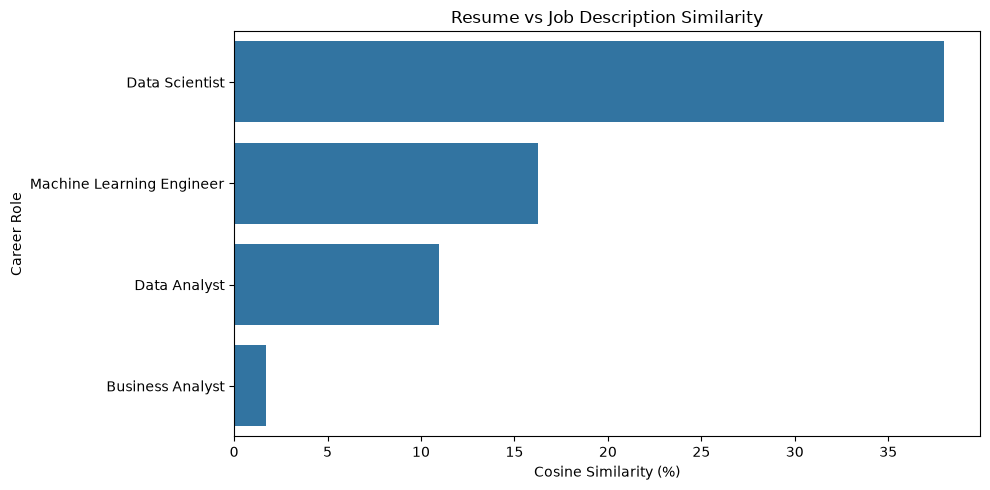

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=ranked_jobs,
    x="Similarity Percentage",
    y="Job Role"
)

plt.title("Resume vs Job Description Similarity")
plt.xlabel("Cosine Similarity (%)")
plt.ylabel("Career Role")
plt.tight_layout()
plt.show()

In [68]:
output_file = NLP_OUTPUT_PATH / "tfidf_job_recommendations.csv"

ranked_jobs.to_csv(output_file, index=False)

print("TF-IDF recommendations saved!")
print("Location:", output_file)

TF-IDF recommendations saved!
Location: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/processed/nlp/tfidf_job_recommendations.csv


In [69]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

In [70]:
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("Sentence Transformer loaded successfully!")

/Users/rizwansalim/Desktop/SkillBridgeByZequa/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Sentence Transformer loaded successfully!


In [71]:
sentences = [
    "I develop machine learning models using Python.",
    "I build predictive artificial intelligence systems.",
    "I analyse business data using SQL and Excel.",
    "I create mobile applications using Android."
]

embeddings = embedding_model.encode(
    sentences,
    convert_to_numpy=True
)

print("Embedding shape:", embeddings.shape)
print("First embedding:")
print(embeddings[0][:10])

Embedding shape: (4, 384)
First embedding:
[-0.0547816  -0.07161955 -0.03375421  0.02935176  0.01542105 -0.15612097
 -0.04822339  0.05323946 -0.03935754 -0.02250799]


In [72]:
similarity_matrix = cosine_similarity(embeddings)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=["Sentence 1", "Sentence 2", "Sentence 3", "Sentence 4"],
    columns=["Sentence 1", "Sentence 2", "Sentence 3", "Sentence 4"]
)

display(similarity_df.round(3))

,Sentence 1,Sentence 2,Sentence 3,Sentence 4
Sentence 1,1.000,0.585,0.348,0.307
Sentence 2,0.585,1.000,0.244,0.173
Sentence 3,0.348,0.244,1.000,0.211
Sentence 4,0.307,0.173,0.211,1.000


In [73]:
resume_embedding = embedding_model.encode(
    [cleaned_resume],
    convert_to_numpy=True
)

job_embeddings = embedding_model.encode(
    job_df["Description"].tolist(),
    convert_to_numpy=True
)

semantic_scores = cosine_similarity(
    resume_embedding,
    job_embeddings
).flatten()

semantic_results = job_df[["Job Role"]].copy()

semantic_results["Semantic Similarity"] = (
    semantic_scores * 100
).round(2)

semantic_results = semantic_results.sort_values(
    "Semantic Similarity",
    ascending=False
).reset_index(drop=True)

display(semantic_results)

,Job Role,Semantic Similarity
0,Data Scientist,56.130001
1,Data Analyst,35.029999
2,Machine Learning Engineer,25.879999
3,Business Analyst,20.600000


In [74]:
semantic_results.to_csv(
    NLP_OUTPUT_PATH / "semantic_job_recommendations.csv",
    index=False
)

print("Semantic recommendations saved successfully!")

Semantic recommendations saved successfully!


In [75]:
semantic_skills = (
    nlp_skills[["Skill ID", "Skill Name", "Source"]]
    .dropna(subset=["Skill Name"])
    .drop_duplicates()
    .copy()
)

semantic_skills["Skill Name"] = (
    semantic_skills["Skill Name"].astype(str).str.strip()
)

semantic_skills = semantic_skills[
    semantic_skills["Skill Name"] != ""
].reset_index(drop=True)

print("Total skill records:", len(semantic_skills))
print("Unique skill names:", semantic_skills["Skill Name"].nunique())

Total skill records: 13949
Unique skill names: 13949


In [76]:
skill_embeddings = embedding_model.encode(
    semantic_skills["Skill Name"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("Skill embedding shape:", skill_embeddings.shape)

Batches: 100%|██████████| 218/218 [02:06<00:00,  1.72it/s]


Skill embedding shape: (13949, 384)


In [77]:
resume_embedding = embedding_model.encode(
    [cleaned_resume],
    convert_to_numpy=True
)

print("Resume embedding shape:", resume_embedding.shape)

Resume embedding shape: (1, 384)


In [78]:
skill_similarity = cosine_similarity(
    resume_embedding,
    skill_embeddings
).flatten()

semantic_skills["Similarity Score"] = skill_similarity

semantic_skills["Similarity Percentage"] = (
    skill_similarity * 100
).round(2)

ranked_skills = semantic_skills.sort_values(
    "Similarity Score",
    ascending=False
).reset_index(drop=True)

display(
    ranked_skills[
        ["Skill Name", "Source", "Similarity Percentage"]
    ].head(30)
)

,Skill Name,Source,Similarity Percentage
0,data science,ESCO,49.849998
1,computer science,ESCO,44.279999
2,training subject expertise,ESCO,41.040001
3,perform data analysis,ESCO,39.650002
4,carry out job analysis,ESCO,38.970001
5,data warehouse,ESCO,37.590000
6,provide career counselling,ESCO,37.110001
7,design job analysis tools,ESCO,36.619999
8,category specific expertise,ESCO,36.540001
9,teach computer science,ESCO,36.490002


In [79]:
SIMILARITY_THRESHOLD = 0.40

matched_semantic_skills = ranked_skills[
    ranked_skills["Similarity Score"] >= SIMILARITY_THRESHOLD
].copy()

print("Total matched skill records:",
      len(matched_semantic_skills))

display(matched_semantic_skills.head(30))

Total matched skill records: 3


,Skill ID,Skill Name,Source,Similarity Score,Similarity Percentage
0,http://data.europa.eu/esco/skill/edebd83d-35f6...,data science,ESCO,0.498549,49.849998
1,http://data.europa.eu/esco/skill/7b5cce4d-c7fe...,computer science,ESCO,0.442842,44.279999
2,http://data.europa.eu/esco/skill/4f6e68b2-85c8...,training subject expertise,ESCO,0.410377,41.040001


In [80]:
semantic_skills_output = (
    NLP_OUTPUT_PATH / "semantic_skill_matches.csv"
)

matched_semantic_skills.to_csv(
    semantic_skills_output,
    index=False
)

print("Semantic skill matching completed!")
print("Saved:", semantic_skills_output)

Semantic skill matching completed!
Saved: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/processed/nlp/semantic_skill_matches.csv


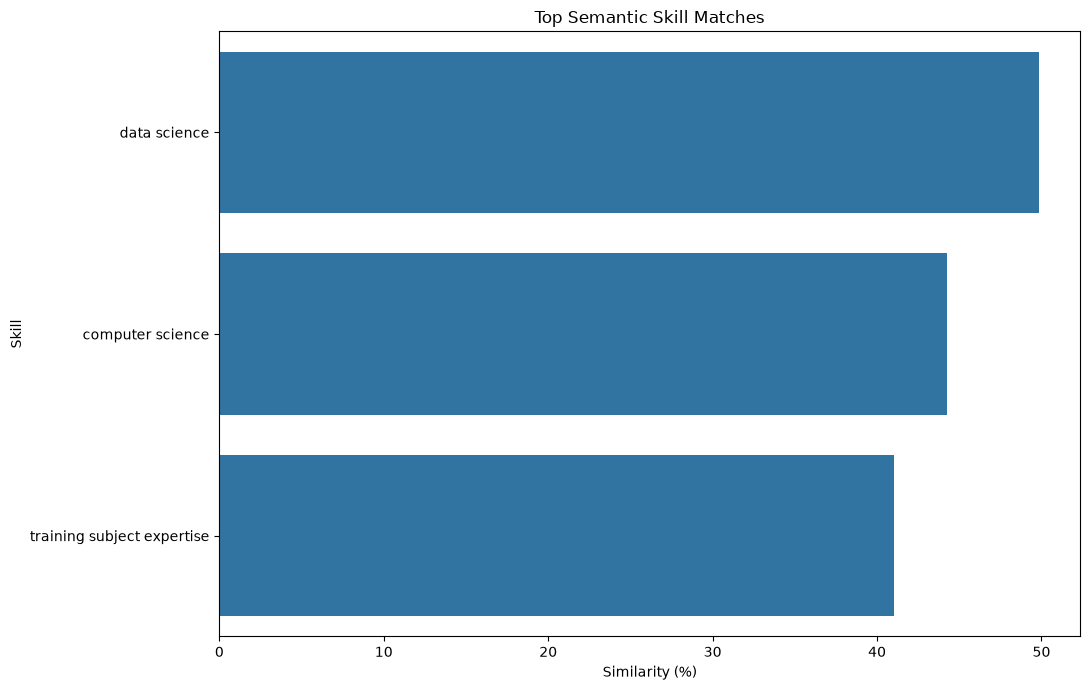

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

top_skills = matched_semantic_skills.head(15)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_skills,
    x="Similarity Percentage",
    y="Skill Name"
)

plt.title("Top Semantic Skill Matches")
plt.xlabel("Similarity (%)")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

In [82]:
from sklearn.metrics import precision_score, recall_score, f1_score

expected_skills = {
    "Python",
    "SQL",
    "Machine Learning",
    "Data Analysis",
    "Deep Learning",
    "TensorFlow",
    "Pandas",
    "NumPy"
}

predicted_skills = set(
    extracted_skills["Skill Name"].str.casefold()
)

expected_normalized = {
    skill.casefold() for skill in expected_skills
}

true_positive = len(predicted_skills & expected_normalized)
false_positive = len(predicted_skills - expected_normalized)
false_negative = len(expected_normalized - predicted_skills)

precision = true_positive / (true_positive + false_positive) if true_positive + false_positive else 0
recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print("True Positives:", true_positive)
print("False Positives:", false_positive)
print("False Negatives:", false_negative)
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 Score: {f1:.3f}")

True Positives: 2
False Positives: 3
False Negatives: 6
Precision: 0.400
Recall: 0.250
F1 Score: 0.308


In [83]:
comparison = ranked_jobs[
    ["Job Role", "Similarity Percentage"]
].merge(
    semantic_results[
        ["Job Role", "Semantic Similarity"]
    ],
    on="Job Role"
)

comparison = comparison.sort_values(
    "Semantic Similarity",
    ascending=False
)

display(comparison)

,Job Role,Similarity Percentage,Semantic Similarity
0,Data Scientist,38.01,56.130001
2,Data Analyst,10.95,35.029999
1,Machine Learning Engineer,16.26,25.879999
3,Business Analyst,1.72,20.600000


In [84]:
evaluation_results = pd.DataFrame({
    "Metric": [
        "True Positives",
        "False Positives",
        "False Negatives",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Value": [
        true_positive,
        false_positive,
        false_negative,
        precision,
        recall,
        f1
    ]
})

evaluation_results.to_csv(
    NLP_OUTPUT_PATH / "nlp_evaluation_results.csv",
    index=False
)

comparison.to_csv(
    NLP_OUTPUT_PATH / "tfidf_vs_semantic_comparison.csv",
    index=False
)

print("Evaluation results saved!")

Evaluation results saved!


In [85]:
SPACY_MODEL_PATH = PROJECT_ROOT / "models" / "spacy_resume_model"

SPACY_MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

nlp.to_disk(SPACY_MODEL_PATH)

print("spaCy model saved:", SPACY_MODEL_PATH)

spaCy model saved: /Users/rizwansalim/Desktop/SkillBridgeByZequa/models/spacy_resume_model


In [86]:
SENTENCE_MODEL_PATH = PROJECT_ROOT / "models" / "sentence_transformer"

embedding_model.save(str(SENTENCE_MODEL_PATH))

print("Sentence Transformer saved:", SENTENCE_MODEL_PATH)

Sentence Transformer saved: /Users/rizwansalim/Desktop/SkillBridgeByZequa/models/sentence_transformer


In [87]:
report = f"""
SKILLBRIDGE BY ZEQUA
DAY 5 - NLP DEVELOPMENT REPORT

=====================================

NLP DATA
--------
Occupation records: {len(nlp_occupations)}
Skill records: {len(nlp_skills)}

SKILL EXTRACTION
----------------
Extracted skills: {len(extracted_skills)}

SEMANTIC MATCHING
-----------------
Semantic skill matches: {len(matched_semantic_skills)}

MODEL EVALUATION
----------------
Precision: {precision:.4f}
Recall: {recall:.4f}
F1 Score: {f1:.4f}

JOB RECOMMENDATIONS
-------------------
TF-IDF roles evaluated: {len(ranked_jobs)}
Semantic roles evaluated: {len(semantic_results)}

MODELS
------
spaCy model: Saved
Sentence Transformer: Saved

=====================================
End of Day 5 Report
"""

report_path = NLP_OUTPUT_PATH / "day5_nlp_report.txt"

report_path.write_text(report, encoding="utf-8")

print(report)
print("Report saved:", report_path)


SKILLBRIDGE BY ZEQUA
DAY 5 - NLP DEVELOPMENT REPORT


NLP DATA
--------
Occupation records: 4055
Skill records: 13949

SKILL EXTRACTION
----------------
Extracted skills: 5

SEMANTIC MATCHING
-----------------
Semantic skill matches: 3

MODEL EVALUATION
----------------
Precision: 0.4000
Recall: 0.2500
F1 Score: 0.3077

JOB RECOMMENDATIONS
-------------------
TF-IDF roles evaluated: 4
Semantic roles evaluated: 4

MODELS
------
spaCy model: Saved
Sentence Transformer: Saved

End of Day 5 Report

Report saved: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/processed/nlp/day5_nlp_report.txt


In [88]:
print("DAY 5 OUTPUT VALIDATION")
print("=======================")

for file in sorted(NLP_OUTPUT_PATH.iterdir()):
    if file.is_file():
        print(
            file.name,
            "|",
            round(file.stat().st_size / 1024, 2),
            "KB"
        )

DAY 5 OUTPUT VALIDATION
day5_nlp_report.txt | 0.56 KB
nlp_evaluation_results.csv | 0.12 KB
nlp_occupations.csv | 361.62 KB
nlp_skills.csv | 1405.78 KB
preprocessed_occupations.csv | 467.64 KB
preprocessed_skills.csv | 1790.21 KB
resume_matched_skills.csv | 0.67 KB
sample_resume_extracted_skills.csv | 0.52 KB
semantic_job_recommendations.csv | 0.12 KB
semantic_skill_matches.csv | 0.39 KB
spacy_pipeline_analysis.csv | 1.23 KB
tfidf_job_recommendations.csv | 0.73 KB
tfidf_vs_semantic_comparison.csv | 0.16 KB
tokenized_occupations.csv | 611.46 KB
tokenized_skills.csv | 2308.11 KB
